In [1]:
"""
    Last modified: 11/21/26 
    
"""

import matplotlib.pyplot as plt
import numpy as np
import astropy.io.ascii as ascii

from scipy.stats import binned_statistic

from tqdm import tqdm

from scipy.stats import norm

import matplotlib.lines as mlines

In [2]:
import sys
print(sys.version)  # Python version

import pandas
import matplotlib, astropy, tqdm, scipy

print(np.__version__)
print(pandas.__version__)
print(astropy.__version__)
print(tqdm.__version__)
print(matplotlib.__version__)
print(scipy.__version__)

3.11.5 (main, Sep 11 2023, 08:31:25) [Clang 14.0.6 ]
1.26.4
3.0.1
7.2.0
4.65.0
3.10.8
1.17.1


In [3]:
#DES sim
# P21 = ascii.read("../sims/DES/FITOPT000_DES_P21.FITRES")
# P21_corr = ascii.read("../sims/DES/FITOPT000_DES_P21_EBV_IGM_MAX.FITRES")

P21 = ascii.read("../sims/DES/FITOPT000_DES_NEW_P21.FITRES")
P21_corr = ascii.read("../sims/DES/FITOPT000_DES_NEW_P21_EBV_IGM_MAX.FITRES")

In [4]:
P21_shallow_filt = (np.abs(P21['c']) < 0.3) & (np.isin(P21['FIELD'],['E1','E2','S1','S2','X1','X2','C1','C2'])) & (np.abs(P21['x1']) < 3) & (P21['x1ERR'] < 1) & (P21['PKMJDERR'] < 2) & (P21['FITPROB'] > 0.001) & (P21['SIM_AV'] > -9)
P21_corr_shallow_filt = (np.abs(P21_corr['c']) < 0.3) & (np.isin(P21_corr['FIELD'],['E1','E2','S1','S2','X1','X2','C1','C2'])) & (np.abs(P21_corr['x1']) < 3) & (P21_corr['x1ERR'] < 1) & (P21_corr['PKMJDERR'] < 2) & (P21_corr['FITPROB'] > 0.001) & (P21_corr['SIM_AV'] > -9)

In [5]:
P21_deep_filt = (np.abs(P21['c']) < 0.3) & (np.isin(P21['FIELD'],['X3','C3'])) & (np.abs(P21['x1']) < 3) & (P21['x1ERR'] < 1) & (P21['PKMJDERR'] < 2) & (P21['FITPROB'] > 0.001) & (P21['SIM_AV'] > -9)
P21_corr_deep_filt = (np.abs(P21_corr['c']) < 0.3) & (np.isin(P21_corr['FIELD'],['X3','C3'])) & (np.abs(P21_corr['x1']) < 3) & (P21_corr['x1ERR'] < 1) & (P21_corr['PKMJDERR'] < 2) & (P21_corr['FITPROB'] > 0.001) & (P21_corr['SIM_AV'] > -9)

In [6]:
P21_total_filt = (np.abs(P21['c']) < 0.3) & (np.abs(P21['x1']) < 3) & (P21['x1ERR'] < 1) & (P21['PKMJDERR'] < 2) & (P21['FITPROB'] > 0.001) & (P21['SIM_AV'] > -9)
P21_corr_total_filt = (np.abs(P21_corr['c']) < 0.3) & (np.abs(P21_corr['x1']) < 3) & (P21_corr['x1ERR'] < 1) & (P21_corr['PKMJDERR'] < 2) & (P21_corr['FITPROB'] > 0.001) & (P21_corr['SIM_AV'] > -9)

In [7]:
print("******* DES sims *******")
print("N\tz_min\tz_max")
print()
print("Total")
print(f"{len(P21[P21_total_filt])}\t{np.min(P21['zHD'][P21_total_filt]):.2f}\t{np.max(P21['zHD'][P21_total_filt]):.2f}")
# print(f"{len(P21_corr[P21_corr_total_filt])}\t{np.min(P21_corr['zHD'][P21_corr_total_filt]):.2f}\t{np.max(P21_corr['zHD'][P21_corr_total_filt]):.2f}")
print()
print("Deep")
print(f"{len(P21[P21_deep_filt])}\t{np.min(P21['zHD'][P21_deep_filt]):.2f}\t{np.max(P21['zHD'][P21_deep_filt]):.2f}")
# print(f"{len(P21_corr[P21_corr_deep_filt])}\t{np.min(P21_corr['zHD'][P21_corr_deep_filt]):.2f}\t{np.max(P21_corr['zHD'][P21_corr_deep_filt]):.2f}")

******* DES sims *******
N	z_min	z_max

Total
354102	0.05	1.20

Deep
130902	0.05	1.20


In [8]:
def bin_vals(x,y,num_bins=30):
    bin_edges = np.linspace(np.min(x),np.max(x),num_bins+1)
    
    bin_means, _, _ = binned_statistic(x,y,statistic='median',bins=bin_edges)
    bin_std, _, _ = binned_statistic(x,y,statistic='std',bins=bin_edges)
    bin_count, _, _ = binned_statistic(x,y,statistic='count',bins=bin_edges)
    
    bin_std_errors = bin_std/np.sqrt(bin_count)
    
    return bin_edges, bin_means, bin_std_errors

# Figure 1

### Top panel

In [9]:
bin_edges = np.arange(np.min(P21_corr['zHD'][P21_corr_deep_filt]),np.max(P21_corr['zHD'][P21_corr_deep_filt]),0.06)

In [10]:
print(bin_edges)

[0.05078 0.11078 0.17078 0.23078 0.29078 0.35078 0.41078 0.47078 0.53078
 0.59078 0.65078 0.71078 0.77078 0.83078 0.89078 0.95078 1.01078 1.07078
 1.13078 1.19078]


In [11]:
bin_count_P21_shallow, _, _ = binned_statistic(P21['zHD'][P21_shallow_filt],P21['zHD'][P21_shallow_filt],statistic='count',bins=bin_edges)

bin_count_P21_corr_shallow, _, _ = binned_statistic(P21_corr['zHD'][P21_corr_shallow_filt],P21_corr['zHD'][P21_corr_shallow_filt],statistic='count',bins=bin_edges)

In [12]:
bin_count_P21_deep, _, _ = binned_statistic(P21['zHD'][P21_deep_filt],P21['zHD'][P21_deep_filt],statistic='count',bins=bin_edges)

bin_count_P21_corr_deep, _, _ = binned_statistic(P21_corr['zHD'][P21_corr_deep_filt],P21_corr['zHD'][P21_corr_deep_filt],statistic='count',bins=bin_edges)

In [13]:
def find_drop(x,y):
    small_drop = True
    i=0
    while (small_drop == True):
        if (y[i]-y[i+1]) > 0.01:
            z_drop = (x[i]+x[i+1])/2
            small_drop = False
        i+=1
        
    return z_drop

In [14]:
bin_zs = (bin_edges[:-1] + bin_edges[1:])/2

z_drop_shallow = find_drop(bin_zs,bin_count_P21_corr_shallow/bin_count_P21_shallow)
z_drop_deep = find_drop(bin_zs,bin_count_P21_corr_deep/bin_count_P21_deep)

In [15]:
print(z_drop_shallow)
print(z_drop_deep)

0.5307799999999999
0.8307799999999999


### Bottom panel

In [16]:
bin_edges_P21_shallow, c_bin_means_P21_shallow, c_bin_std_P21_shallow = bin_vals(P21['zHD'][P21_shallow_filt],P21['c'][P21_shallow_filt],num_bins=len(bin_zs))
bin_edges_P21_corr_shallow, c_bin_means_P21_corr_shallow, c_bin_std_P21_corr_shallow = bin_vals(P21_corr['zHD'][P21_corr_shallow_filt],P21_corr['c'][P21_corr_shallow_filt],num_bins=len(bin_zs))

In [17]:
bin_edges_P21_deep, c_bin_means_P21_deep, c_bin_std_P21_deep = bin_vals(P21['zHD'][P21_deep_filt],P21['c'][P21_deep_filt],num_bins=len(bin_zs))
bin_edges_P21_corr_deep, c_bin_means_P21_corr_deep, c_bin_std_P21_corr_deep = bin_vals(P21_corr['zHD'][P21_corr_deep_filt],P21_corr['c'][P21_corr_deep_filt],num_bins=len(bin_zs))

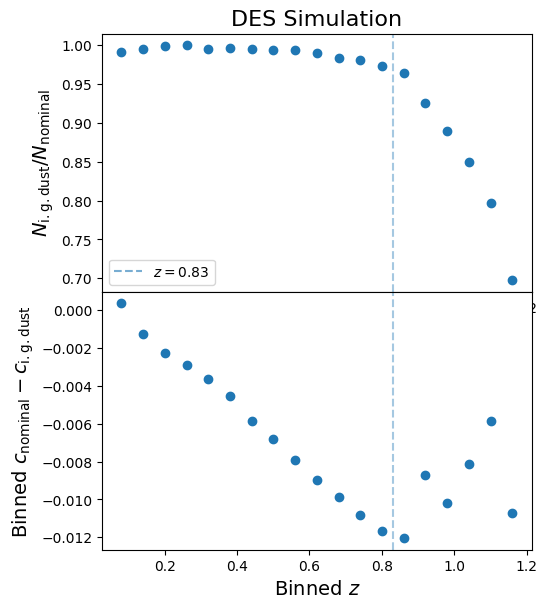

In [18]:
fig = plt.figure(figsize=(5,6))

ax1 = fig.add_axes([0.08, 0.52, 0.86, 0.43])

plt.scatter(bin_zs,
            bin_count_P21_corr_deep/bin_count_P21_deep,zorder=2)
plt.axvline(x=z_drop_deep,
            color='C0',ls='--',alpha=0.4)

ax = plt.gca()
blue_dotted = mlines.Line2D([], [], color="C0", linestyle="--", label=f"$z={z_drop_deep:.2f}$",alpha=0.6)
legend2 = ax.legend(handles=[blue_dotted],loc='lower left')

plt.title("DES Simulation",fontsize=16)
plt.ylabel("$N_\mathrm{i.g. dust}/N_\mathrm{nominal}$",fontsize=14)

ax2 = fig.add_axes([0.08, 0.09, 0.86, 0.43])
plt.scatter(bin_zs,c_bin_means_P21_deep-c_bin_means_P21_corr_deep,zorder=2)
plt.xlabel("Binned $z$",fontsize=14)
plt.ylabel("Binned $c_\mathrm{nominal}-c_\mathrm{i.g. dust}$",fontsize=14)

plt.axvline(x=z_drop_deep,
            color='C0',ls='--',alpha=0.4)


# plt.savefig("pngs/DES_sim_compare.png",bbox_inches='tight')
# plt.savefig("pdfs/DES_sim_compare.pdf",bbox_inches='tight')
plt.show()

# Figure 2

In [19]:
datastr = "../DES_data/maria_files/FITOPT000_DATA.FITRES"
data = ascii.read(datastr)

In [20]:
deep_data_z_filt = (data['PROB_SNNV19'] > 0.5) & (np.isin(data['FIELD'],['X3','C3'])) & (data['IDSURVEY']==10) & (np.abs(data['c'])<0.3) & (np.abs(data['x1'])<3) & (np.abs(data['x1ERR'])<1) & (np.abs(data['PKMJDERR'])<2) & (np.abs(data['FITPROB'])>0.001)
total_data_z_filt = (data['PROB_SNNV19'] > 0.5) & (data['IDSURVEY']==10) & (np.abs(data['c'])<0.3) & (np.abs(data['x1'])<3) & (np.abs(data['x1ERR'])<1) & (np.abs(data['PKMJDERR'])<2) & (np.abs(data['FITPROB'])>0.001)

print("******* DES data *******")
print("N\tz_min\tz_max")
print()
print("Total")
print(f"{len(data[total_data_z_filt])}\t{np.min(data['zHD'][total_data_z_filt]):.2f}\t{np.max(data['zHD'][total_data_z_filt]):.2f}")
print()
print("Deep")
print(f"{len(data[deep_data_z_filt])}\t{np.min(data['zHD'][deep_data_z_filt]):.2f}\t{np.max(data['zHD'][deep_data_z_filt]):.2f}")

******* DES data *******
N	z_min	z_max

Total
1627	0.06	1.17

Deep
494	0.08	1.17


In [21]:
shallow_data_z_filt = (data['zHD'] <= z_drop_shallow) & (data['PROB_SNNV19'] > 0.5) & (np.isin(data['FIELD'],['E1','E2','S1','S2','X1','X2','C1','C2'])) & (data['IDSURVEY']==10) & (np.abs(data['c'])<0.3) & (np.abs(data['x1'])<3) & (np.abs(data['x1ERR'])<1) & (np.abs(data['PKMJDERR'])<2) & (np.abs(data['FITPROB'])>0.001)
print(f"{len(data[shallow_data_z_filt])} SNe in the DES Shallow fields at z < {z_drop_shallow:.2f} that pass cuts")

646 SNe in the DES Shallow fields at z < 0.53 that pass cuts


In [22]:
""" MEANS splitting by field shallow/deep """
def calc_c_vs_z(data,sims_list,zmin=0.0,zmax=0.1,delta=0.1,N=10,offset=0):
    sim = sims_list[0]
    
    zmin = 0.1
    zmax = 0.2
    delta = 0.1 #was at 0.2 and zmax at 0.3

    z_means = []
    shallow_data_c_means = []
    shallow_data_c_stds = []

    shallow_sim_c_means = []
    shallow_sim_c_stds = []
    
    deep_data_c_means = []
    deep_data_c_stds = []

    deep_sim_c_means = []
    deep_sim_c_stds = []

    
    total_N_data = 0

    for i in range(N): #was at 5
        shallow_data_z_filt = (data['zHD'] <= z_drop_shallow) & (data['zHD'] > zmin) & (data['zHD'] <= zmax) & (data['PROB_SNNV19'] > 0.5) & (np.isin(data['FIELD'],['E1','E2','S1','S2','X1','X2','C1','C2'])) & (data['IDSURVEY']==10) & (np.abs(data['c'])<0.3) & (np.abs(data['x1'])<3) & (np.abs(data['x1ERR'])<1) & (np.abs(data['PKMJDERR'])<2) & (np.abs(data['FITPROB'])>0.001)

        bins = np.arange(-0.3,0.35,0.05)

        #data  
        if (z_drop_shallow - zmin) > 0.04:
            shallow_data_c_means.append(np.mean(data['c'][shallow_data_z_filt]))
            shallow_data_c_stds.append(np.std(data['c'][shallow_data_z_filt])/np.sqrt(len(data['c'][shallow_data_z_filt])))

        deep_data_z_filt = (data['zHD'] <= z_drop_deep) & (data['zHD'] > zmin) & (data['zHD'] <= zmax) & (data['PROB_SNNV19'] > 0.5) & (np.isin(data['FIELD'],['X3','C3'])) & (data['IDSURVEY']==10) & (np.abs(data['c'])<0.3) & (np.abs(data['x1'])<3) & (np.abs(data['x1ERR'])<1) & (np.abs(data['PKMJDERR'])<2) & (np.abs(data['FITPROB'])>0.001)

        if (z_drop_deep - zmin) > 0.04:
            deep_data_c_means.append(np.mean(data['c'][deep_data_z_filt]))
            deep_data_c_stds.append(np.std(data['c'][deep_data_z_filt])/np.sqrt(len(data['c'][deep_data_z_filt])))

        total_N_data+=len(data[shallow_data_z_filt])
        total_N_data+=len(data[deep_data_z_filt])

        
        #sims
        shallow_sim_z_filt = (sim['zHD'] <= z_drop_shallow) & (sim['zHD'] > zmin) & (sim['zHD'] <= zmax) & (np.abs(sim['c']) < 0.3) & (np.isin(sim['FIELD'],['E1','E2','S1','S2','X1','X2','C1','C2'])) & (np.abs(sim['x1']) < 3) & (sim['x1ERR'] < 1) & (sim['PKMJDERR'] < 2) & (sim['FITPROB'] > 0.001) & (sim['SIM_AV'] > -9)

        if (z_drop_shallow - zmin) > 0.04:
            shallow_sim_c_means.append(np.mean(sim['c'][shallow_sim_z_filt])+offset)
            shallow_sim_c_stds.append(np.std(sim['c'][shallow_sim_z_filt])/np.sqrt(len(sim['c'][shallow_sim_z_filt])))

        deep_sim_z_filt = (sim['zHD'] <= z_drop_deep) & (sim['zHD'] > zmin) & (sim['zHD'] <= zmax) & (np.abs(sim['c']) < 0.3) & (np.isin(sim['FIELD'],['X3','C3'])) & (np.abs(sim['x1']) < 3) & (sim['x1ERR'] < 1) & (sim['PKMJDERR'] < 2) & (sim['FITPROB'] > 0.001) & (sim['SIM_AV'] > -9)

        if (z_drop_deep - zmin) > 0.04:
            deep_sim_c_means.append(np.mean(sim['c'][deep_sim_z_filt])+offset)
            deep_sim_c_stds.append(np.std(sim['c'][deep_sim_z_filt])/np.sqrt(len(sim['c'][deep_sim_z_filt])))

        z_means.append((zmin+zmax)/2)                           


        zmin+=delta
        zmax+=delta
    print(total_N_data)
    
    
    z_means = np.array(z_means)
    shallow_data_c_means = np.array(shallow_data_c_means)
    shallow_data_c_stds = np.array(shallow_data_c_stds)
    shallow_sim_c_means = np.array(shallow_sim_c_means)
    shallow_sim_c_stds = np.array(shallow_sim_c_stds)
    
    deep_data_c_means = np.array(deep_data_c_means)
    deep_data_c_stds = np.array(deep_data_c_stds)
    deep_sim_c_means = np.array(deep_sim_c_means)
    deep_sim_c_stds = np.array(deep_sim_c_stds)
    
    return (z_means,shallow_data_c_means,shallow_data_c_stds,shallow_sim_c_means,shallow_sim_c_stds,deep_data_c_means,deep_data_c_stds,deep_sim_c_means,deep_sim_c_stds)

In [23]:
def plot_c_vs_z(z,c,cerr=[],label='',sim=True,color='C0'):
    """ plot one at a time (don't say plt.show()) """
    #sims
    if sim == True:
        plt.plot(z,c,label=label,color=color)
        if len(cerr)>0:
            plt.errorbar(z,c,yerr=cerr,ls='none',zorder=1,alpha=0.8,color=color,capsize=2,lw=2)
    #data
    else:
        plt.scatter(z,c,label=label,color=color)
        if len(cerr)>0:
            plt.errorbar(z,c,yerr=cerr,ls='none',zorder=1,alpha=0.4,color=color)
        
    
        
    plt.xlabel("$z$",fontsize=16)
    plt.ylabel("mean $c$",fontsize=16)
#     plt.xlim(0.0,1.1)
#     plt.ylim(-0.12,0.07)
    plt.legend(loc='upper right',fontsize=16)

In [24]:
def chi2(data,sim,data_err):
    return np.sum((np.array(data)-np.array(sim))**2/np.array(data_err)**2)

In [25]:
#Paper Figure!
mz,sdc,sdc_s,ssc,ssc_s,ddc,ddc_s,dsc,dsc_s = calc_c_vs_z(data,[P21],zmin=0.1,zmax=0.2)
_,_,_,ssc2,ssc_s2,_,_,dsc2,dsc_s2 = calc_c_vs_z(data,[P21],zmin=0.1,zmax=0.2)
_,_,_,ssc3,ssc_s3,_,_,dsc3,dsc_s3 = calc_c_vs_z(data,[P21_corr],zmin=0.1,zmax=0.2)

1048
1048
1048


In [26]:
#Fit for an offset between Data and Sim

def weighted_mean_difference(A, B, sigma_A, sigma_B):
    """
    Compute the weighted mean difference between two datasets A and B,
    taking into account their uncertainties sigma_A and sigma_B.

    Parameters:
    A (array-like): First set of values.
    B (array-like): Second set of values.
    sigma_A (array-like): Uncertainties associated with A.
    sigma_B (array-like): Uncertainties associated with B.

    Returns:
    tuple: (weighted mean difference, uncertainty of the weighted mean)
    """
    # Compute differences and propagated uncertainties
    D = np.array(A) - np.array(B)
    sigma_D = np.sqrt(np.array(sigma_A)**2 + np.array(sigma_B)**2)

    # Compute weighted mean difference
    weights = 1 / sigma_D**2
    D_mean = np.sum(D * weights) / np.sum(weights)

    # Compute uncertainty of the weighted mean
    sigma_D_mean = np.sqrt(1 / np.sum(weights))

    return D_mean, sigma_D_mean

In [27]:
wmd2 = weighted_mean_difference(dsc2,ddc,dsc_s2,ddc_s)[0]
wmd3 = weighted_mean_difference(dsc3,ddc,dsc_s3,ddc_s)[0]
print(wmd2)
print(wmd3)

0.01070757550422678
0.01717337877588982


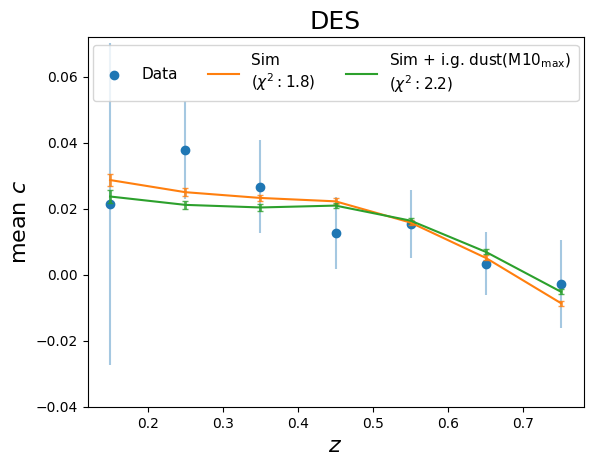

In [28]:
plt.title("DES",fontsize=18)
plot_c_vs_z(mz[0:len(ddc)],ddc,cerr=ddc_s,label='Data',sim=False)
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc2)-wmd2,cerr=dsc_s2,label=f'Sim \n($\chi^2:{chi2(ddc,dsc2-wmd2,ddc_s):.1f}$)',color='C1')
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc3)-wmd3,cerr=dsc_s3,label=f'Sim + i.g. dust(M10$_\mathrm{{max}}$) \n($\chi^2:{chi2(ddc,dsc3-wmd3,ddc_s):.1f}$)',color='C2')
plt.legend(loc='upper center',fontsize=11,ncol=3)
# ax2.get_legend().remove()
plt.ylim(-0.04,0.072)
# plt.xlim(0,1)

# plt.savefig("pngs/DES_compare_c_vs_z.png",bbox_inches='tight')
# plt.savefig("pdfs/DES_compare_c_vs_z.pdf",bbox_inches='tight')
plt.show()

# Figure 3
### - Multiplications of i.g. dust too for DES  

In [29]:
P21_corr3 = ascii.read("../sims/DES/FITOPT000_DES_NEW_P21_EBV_IGM_MAX_x3.FITRES")
P21_corr5 = ascii.read("../sims/DES/FITOPT000_DES_NEW_P21_EBV_IGM_MAX_x5.FITRES")

In [30]:
_,_,_,ssc4,ssc_s4,_,_,dsc4,dsc_s4 = calc_c_vs_z(data,[P21_corr3],zmin=0.1,zmax=0.2)
_,_,_,ssc5,ssc_s5,_,_,dsc5,dsc_s5 = calc_c_vs_z(data,[P21_corr5],zmin=0.1,zmax=0.2)

1048
1048


In [31]:
wmd4 = weighted_mean_difference(dsc4,ddc,dsc_s4,ddc_s)[0]
wmd5 = weighted_mean_difference(dsc5,ddc,dsc_s5,ddc_s)[0]
print(wmd4)
print(wmd5)

0.030084686247270714
0.042570837975053503


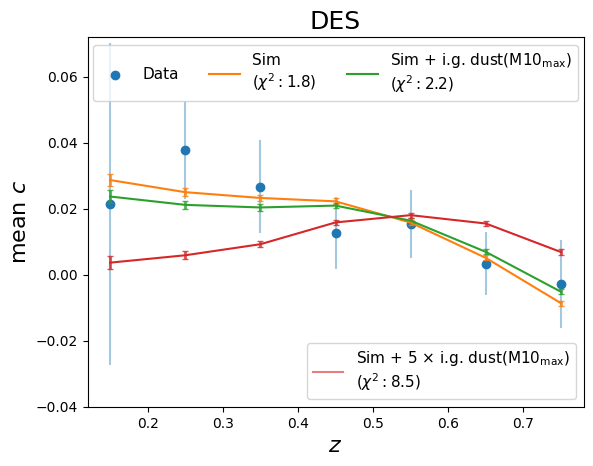

In [34]:
plt.title("DES",fontsize=18)
plot_c_vs_z(mz[0:len(ddc)],ddc,cerr=ddc_s,label='Data',
            sim=False)
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc2)-wmd2,cerr=dsc_s2,label=f'Sim\n($\chi^2:{chi2(ddc,dsc2-wmd2,ddc_s):.1f}$)',
            color='C1')
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc3)-wmd3,cerr=dsc_s3,label=f'Sim + i.g. dust(M10$_\mathrm{{max}}$)\n($\chi^2:{chi2(ddc,dsc3-wmd3,ddc_s):.1f}$)',
            color='C2')

legend1 = plt.legend(loc="upper center",ncol=3,fontsize=11)

# plot_c_vs_z(mz[0:len(ddc)],np.array(dsc4)-wmd4,cerr=dsc_s4,label=None,#f'P21 + 3 x i.g. dust \n($\chi^2:{chi2(ddc,dsc4,ddc_s):.1f}$)',
#             color='C3')
plot_c_vs_z(mz[0:len(ddc)],np.array(dsc5)-wmd5,cerr=dsc_s5,label=None,#f'P21 + 5 x i.g. dust \n($\chi^2:{chi2(ddc,dsc5,ddc_s):.1f}$)',
            color='C3')
ax = plt.gca()
# blue_dotted = mlines.Line2D([], [], color="C3", linestyle="-", label=f'P21 + 3 x i.g. dust(M10$_\mathrm{{max}}$) \n($\chi^2:{chi2(ddc,dsc4-wmd4,ddc_s):.1f}$)',alpha=0.6)
orange_dotted = mlines.Line2D([], [], color="C3", linestyle="-", label=fr'Sim + 5 $\times$ i.g. dust(M10$_\mathrm{{max}}$)' \
+ f'\n($\chi^2:{chi2(ddc,dsc5-wmd5,ddc_s):.1f}$)',alpha=0.6)
legend2 = ax.legend(handles=[orange_dotted],loc='lower right',ncol=1,fontsize=11)

ax.add_artist(legend1)

plt.ylim(-0.04,0.072)
# plt.xlim(0,1)

plt.savefig("pngs/DES_mult_compare_c_vs_z.png",bbox_inches='tight')
plt.savefig("pdfs/DES_mult_compare_c_vs_z.pdf",bbox_inches='tight')
plt.show()